# 03 Distributions

**Question:** What do bid, paying and floor prices look like?

Task 2, step 3: **histograms and percentiles (p50, p90, p99)** of the bid price, the paying price and the floor price. The goal is to **find the skew and the outliers**, and to **try a log scale**.

**Method, chosen to be exact and light on memory.** Prices are whole numbers with few distinct values: 6 bid levels and a few hundred paying and floor prices. One pass over each log counts the rows at every price, per campaign. Every statistic is then computed from those small tables, so the percentiles are **exact**, even over 53 million bids, and nothing is written to disk. Percentiles use the nearest-rank rule: the p-th percentile is the smallest price at or below which at least p% of the rows fall.

**Prices** are per 1,000 impressions, and iPinYou scaled them before release. Compare them with each other, not as money.

**Which rows count:** the **bid** price and the **floor** price are looked at over *all bids* (what we offer and what publishers ask). The **paying** price exists only for *won impressions*.

### Setup

In [1]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

KILL_STALE = False
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert "typed_imp" in views, "Run the loading cells first (typed_imp missing)"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT TRY_CAST(advertiser_id AS BIGINT) AS advertiser_id, "
                "TRY_CAST(bidding_price AS BIGINT) AS bidding_price, "
                "TRY_CAST(ad_slot_floor_price AS BIGINT) AS ad_slot_floor_price FROM read_parquet(["
                + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt in memory from", len(files), "Parquet files")

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
    print("pip install matplotlib for the histograms")
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved, shown here only)")
print("Data:", DATA_SOURCE)

Data: ipinyou.duckdb (the loading notebook's database)


### 1. Count the rows at every price (one pass per log)

In [2]:
# CELL 2: frequency tables (small: a few thousand rows)
t0 = time.time()
bid_vc = q("""SELECT advertiser_id, bidding_price, ad_slot_floor_price, count(*) AS n
              FROM typed_bid GROUP BY ALL""")
print(f"bids: {bid_vc.n.sum():,} rows -> {len(bid_vc):,} price combinations ({time.time() - t0:.0f}s)")
t0 = time.time()
imp_vc = q("""SELECT advertiser_id, bidding_price, paying_price, ad_slot_floor_price, count(*) AS n
              FROM typed_imp GROUP BY ALL""")
print(f"impressions: {imp_vc.n.sum():,} rows -> {len(imp_vc):,} price combinations ({time.time() - t0:.0f}s)")

def counts(df, col, where=None):
    d = df if where is None else df[where(df)]
    return d.groupby(col)["n"].sum().sort_index()

bids: 53,289,330 rows -> 963 price combinations (0s)
impressions: 12,237,087 rows -> 28,015 price combinations (0s)


### 2. Percentiles and shape

For each price the table gives the count, mean, median (p50), p90 and p99, plus:
* **mean / median**: above 1 means a long right tail pulls the mean up
* **skewness**: 0 is symmetric, above 1 is strongly right-skewed
* **excess kurtosis**: above 0 means heavier tails than a normal distribution
* **share at 0**: a spike at zero (free inventory, or no floor) distorts the mean

In [3]:
# CELL 3: exact weighted statistics from the frequency tables
def wstats(vc):
    v = vc.index.to_numpy(float)
    w = vc.to_numpy(float)
    n = w.sum()
    mean = (v * w).sum() / n
    var = (w * (v - mean) ** 2).sum() / (n - 1)
    sd_pop = np.sqrt((w * (v - mean) ** 2).sum() / n)
    skew = (w * (v - mean) ** 3).sum() / n / sd_pop ** 3 if sd_pop > 0 else np.nan
    kurt = (w * (v - mean) ** 4).sum() / n / sd_pop ** 4 - 3 if sd_pop > 0 else np.nan
    cum = np.cumsum(w) / n
    pct = lambda p: v[np.searchsorted(cum, p - 1e-12)]          # nearest-rank percentile
    out = {"n": int(n), "mean": mean, "std": np.sqrt(var), "min": v.min()}
    for p in (1, 5, 25, 50, 75, 90, 95, 99):
        out[f"p{p}"] = pct(p / 100)
    out.update({"max": v.max(), "mean/median": mean / pct(0.5) if pct(0.5) else np.nan,
                "skewness": skew, "excess_kurtosis": kurt, "share_at_0": w[v == 0].sum() / n,
                "distinct_values": int((w > 0).sum())})
    return out

SPECS = {
    "bid price (all bids)": counts(bid_vc, "bidding_price"),
    "bid price (won impressions)": counts(imp_vc, "bidding_price"),
    "paying price (won impressions)": counts(imp_vc, "paying_price"),
    "floor price (all bids)": counts(bid_vc, "ad_slot_floor_price"),
    "floor price > 0 (all bids)": counts(bid_vc, "ad_slot_floor_price", lambda d: d.ad_slot_floor_price > 0),
    "floor price (won impressions)": counts(imp_vc, "ad_slot_floor_price"),
}
summary = pd.DataFrame({k: wstats(v) for k, v in SPECS.items()}).T
display(summary[["n", "mean", "std", "min", "p1", "p5", "p25", "p50", "p75", "p90", "p95", "p99", "max",
                 "mean/median", "skewness", "excess_kurtosis", "share_at_0", "distinct_values"]])

,n,mean,std,min,p1,p5,p25,p50,p75,p90,p95,p99,max,mean/median,skewness,excess_kurtosis,share_at_0,distinct_values
bid price (all bids),"53,289,330.00",272.92,29.84,227.00,227.00,227.00,241.00,300.00,300.00,300.00,300.00,300.00,300.00,0.91,-0.25,-1.82,0.00,6.00
bid price (won impressions),"12,237,087.00",268.49,31.18,227.00,227.00,227.00,238.00,254.00,300.00,300.00,300.00,300.00,300.00,1.06,-0.05,-1.86,0.00,6.00
paying price (won impressions),"12,237,087.00",78.35,58.91,0.00,5.00,11.00,38.00,70.00,92.00,166.00,213.00,260.00,300.00,1.12,1.34,1.51,0.00,301.00
floor price (all bids),"53,289,330.00",47.21,41.04,0.00,0.00,0.00,5.00,50.00,80.00,100.00,100.00,148.00,300.00,0.94,0.45,-0.65,0.11,256.00
floor price > 0 (all bids),"47,170,085.00",53.34,39.69,1.00,4.00,5.00,10.00,50.00,100.00,100.00,100.00,148.00,300.00,1.07,0.31,-0.56,0.00,255.00
floor price (won impressions),"12,237,087.00",26.70,35.78,0.00,0.00,0.00,0.00,5.00,50.00,70.00,80.00,148.00,300.00,5.34,1.73,4.31,0.32,229.00


### 3. Per campaign
Campaigns buy different inventory and bid differently, so pooled numbers can hide very different shapes.

In [4]:
# CELL 4: percentiles per campaign
rows = []
for adv in sorted(imp_vc.advertiser_id.unique()):
    for name, df, col in [("paying price", imp_vc, "paying_price"), ("floor price (bids)", bid_vc, "ad_slot_floor_price")]:
        if not (df.advertiser_id == adv).any():
            print(f"advertiser {adv}: no {name} rows (its bid logs are not loaded), skipped")
            continue
        s = wstats(counts(df[df.advertiser_id == adv], col))
        rows.append({"advertiser_id": adv, "price": name, **{k: s[k] for k in
                     ["n", "mean", "p50", "p90", "p99", "max", "mean/median", "skewness", "share_at_0"]}})
per_campaign = pd.DataFrame(rows)
display(per_campaign)

bl = bid_vc.groupby(["advertiser_id", "bidding_price"]).n.sum().unstack(fill_value=0)
FEW_LEVELS = bl.shape[1] <= 20
if FEW_LEVELS:
    print("Bid levels per campaign (share of the campaign's bids at each bid price):")
    display((bl.div(bl.sum(axis=1), axis=0) * 100).round(1).style.format("{:.1f}%"))
else:
    print(f"{bl.shape[1]} distinct bid prices: treated as a continuous distribution.")

,advertiser_id,price,n,mean,p50,p90,p99,max,mean/median,skewness,share_at_0
0,1458,paying price,3083056,68.89,60.00,147.00,267.00,300.00,1.15,1.74,0.00
1,1458,floor price (bids),14701496,58.67,70.00,100.00,140.00,300.00,0.84,-0.02,0.09
2,3358,paying price,1742104,92.38,77.00,199.00,259.00,267.00,1.20,0.90,0.00
3,3358,floor price (bids),3751016,21.39,5.00,70.00,148.00,238.00,4.28,1.81,0.46
4,3386,paying price,2847802,76.92,67.00,169.00,280.00,300.00,1.15,1.48,0.00
5,3386,floor price (bids),14091931,60.62,70.00,100.00,100.00,300.00,0.87,-0.09,0.07
6,3427,paying price,2593765,81.06,76.00,168.00,254.00,267.00,1.07,1.21,0.00
7,3427,floor price (bids),14032619,31.46,5.00,80.00,162.00,238.00,6.29,1.47,0.08
8,3476,paying price,1970360,79.22,73.00,168.00,252.00,267.00,1.09,1.21,0.00
9,3476,floor price (bids),6712268,41.33,50.00,100.00,100.00,249.00,0.83,0.46,0.14


Bid levels per campaign (share of the campaign's bids at each bid price):


bidding_price,227,238,241,249,254,300
advertiser_id,,,,,,
1458,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%
3358,45.8%,27.6%,26.6%,0.0%,0.0%,0.0%
3386,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%
3427,8.1%,50.8%,41.1%,0.0%,0.0%,0.0%
3476,0.0%,14.2%,0.0%,16.2%,69.5%,0.0%


### 4. Histograms on a linear scale

The orange line marks the median, the dashed line p90 and the dotted line p99. The bid price is a **bar chart of its levels** rather than a histogram, because a campaign bids only a handful of fixed prices.

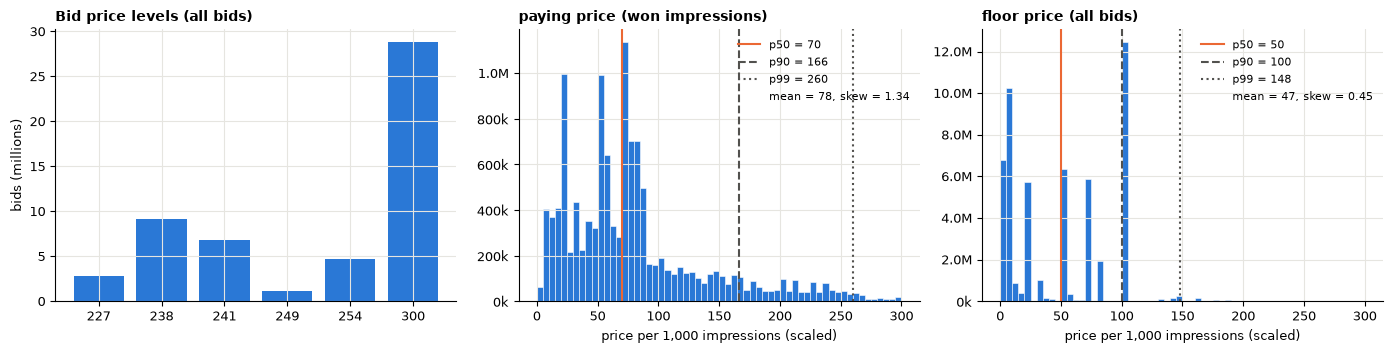

In [5]:
# CELL 5: linear histograms
if plt:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    vc = SPECS["bid price (all bids)"]
    if FEW_LEVELS:
        axes[0].bar(vc.index.astype(str), vc.values / 1e6, color=BLUE)
        axes[0].set_title("Bid price levels (all bids)")
    else:
        axes[0].hist(vc.index, bins=60, weights=vc.values / 1e6, color=BLUE, edgecolor="white", linewidth=0.4)
        axes[0].set_title("Bid price (all bids)")
    axes[0].set_ylabel("bids (millions)")
    for ax, name in zip(axes[1:], ["paying price (won impressions)", "floor price (all bids)"]):
        vc = SPECS[name]
        s = summary.loc[name]
        ax.hist(vc.index, bins=60, weights=vc.values, color=BLUE, edgecolor="white", linewidth=0.4)
        for p, ls, c in (("p50", "-", ORANGE), ("p90", "--", INK2), ("p99", ":", INK2)):
            ax.axvline(s[p], color=c, ls=ls, lw=1.5, label=f"{p} = {s[p]:.0f}")
        ax.plot([], [], " ", label=f"mean = {s['mean']:.0f}, skew = {s['skewness']:.2f}")
        ax.legend(fontsize=8, loc="upper right", frameon=False)
        ax.set_title(name)
        ax.set_xlabel("price per 1,000 impressions (scaled)")
        ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M" if x >= 1e6 else f"{x / 1e3:.0f}k"))
    fig.tight_layout()
    save(fig, "03_hist_linear")
    plt.show()

### 5. The same prices on a log scale

A **log x-axis** spreads out the many cheap prices and squeezes the long tail. If the shape then looks roughly bell-shaped, the price is close to *log-normal*, which is typical for auction prices: the effects multiply rather than add. A **log y-axis** makes the rare expensive prices visible instead of flat against zero.

Zero can't go on a log axis, so prices of 0 are counted and reported separately.

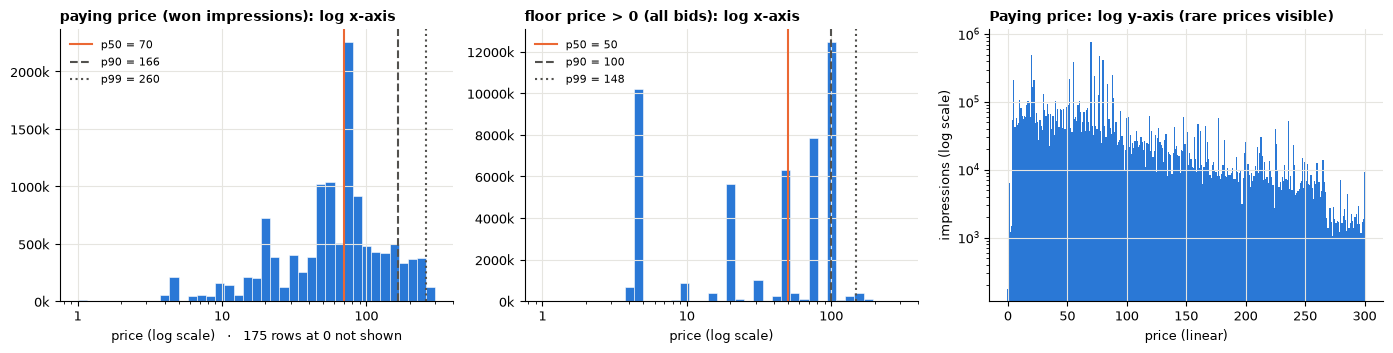

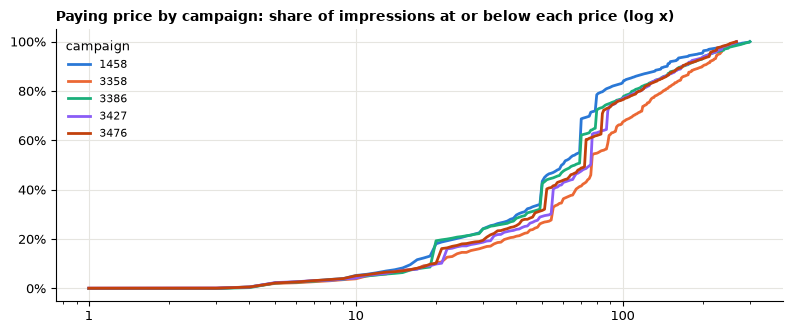

In [6]:
# CELL 6: log scales
if plt:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, name in zip(axes[:2], ["paying price (won impressions)", "floor price > 0 (all bids)"]):
        vc = SPECS[name]
        vc = vc[vc.index > 0]
        zeros = SPECS[name][SPECS[name].index == 0].sum()
        bins = np.logspace(np.log10(max(vc.index.min(), 1)), np.log10(vc.index.max() + 1), 40)
        ax.hist(vc.index, bins=bins, weights=vc.values, color=BLUE, edgecolor="white", linewidth=0.4)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f"{x:g}"))
        s = summary.loc[name]
        for p, ls, c in (("p50", "-", ORANGE), ("p90", "--", INK2), ("p99", ":", INK2)):
            ax.axvline(max(s[p], 1), color=c, ls=ls, lw=1.5, label=f"{p} = {s[p]:.0f}")
        ax.legend(fontsize=8, frameon=False, loc="upper left")
        ax.set_title(f"{name}: log x-axis")
        ax.set_xlabel("price (log scale)" + (f"   ·   {zeros:,.0f} rows at 0 not shown" if zeros else ""))
        ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f"{x / 1e3:.0f}k"))
    vc = SPECS["paying price (won impressions)"]
    axes[2].bar(vc.index, vc.values, width=1.0, color=BLUE)
    axes[2].set_yscale("log")
    axes[2].set_title("Paying price: log y-axis (rare prices visible)")
    axes[2].set_xlabel("price (linear)")
    axes[2].set_ylabel("impressions (log scale)")
    fig.tight_layout()
    save(fig, "03_hist_log")
    plt.show()

    # one more view of skew: the paying-price distribution per campaign, log x
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for adv, c in zip(sorted(imp_vc.advertiser_id.unique()), ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cf6", "#c2410c"]):
        vc = counts(imp_vc[(imp_vc.advertiser_id == adv) & (imp_vc.paying_price > 0)], "paying_price")
        cum = vc.cumsum() / vc.sum()
        ax.plot(vc.index, cum.values, lw=2, color=c, label=str(adv))
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.yaxis.set_major_formatter(mt.PercentFormatter(1.0))
    ax.set_title("Paying price by campaign: share of impressions at or below each price (log x)")
    ax.legend(title="campaign", fontsize=8, frameon=False)
    fig.tight_layout()
    save(fig, "03_cdf_by_campaign")
    plt.show()

### 6. Outliers

Outliers are found three ways, because skewed data breaks the usual rules:
* **IQR fence:** above Q3 + 1.5 × IQR. This is the classic box-plot rule, but on right-skewed data it flags a lot of perfectly normal expensive auctions.
* **IQR fence on log(price):** the same rule after a log transform. It suits skewed prices better.
* **z-score > 3:** assumes a symmetric bell curve, so it is the least reliable here. It is shown for comparison.

Separately, there are **impossible values**: rows that break the auction rules, such as a paying price above the bid. Notebook 01 flagged these. They are data issues, not expensive auctions.

The **top-1% spend share** shows how much of the budget the most expensive impressions take.

In [7]:
# CELL 7: outliers
def outliers(vc):
    s = wstats(vc)
    v, w, n = vc.index.to_numpy(float), vc.to_numpy(float), vc.sum()
    iqr = s["p75"] - s["p25"]
    hi = s["p75"] + 1.5 * iqr
    pos = vc[vc.index > 0]
    lv = np.log(pos.index.to_numpy(float))
    lw_ = pos.to_numpy(float)
    lc = np.cumsum(lw_) / lw_.sum()
    lq1, lq3 = lv[np.searchsorted(lc, 0.25)], lv[np.searchsorted(lc, 0.75)]
    log_hi = np.exp(lq3 + 1.5 * (lq3 - lq1))
    return {"IQR upper fence": hi, "rows above IQR fence": w[v > hi].sum(), "% above IQR fence": 100 * w[v > hi].sum() / n,
            "log-IQR upper fence": log_hi, "rows above log fence": w[v > log_hi].sum(),
            "% above log fence": 100 * w[v > log_hi].sum() / n,
            "z>3 threshold": s["mean"] + 3 * s["std"], "% with z>3": 100 * w[v > s["mean"] + 3 * s["std"]].sum() / n}

out_tab = pd.DataFrame({k: outliers(SPECS[k]) for k in
                        ["paying price (won impressions)", "floor price > 0 (all bids)", "bid price (all bids)"]}).T
display(out_tab)

pay = SPECS["paying price (won impressions)"]
spend = pay.index.to_numpy(float) * pay.to_numpy(float)
p99 = summary.loc["paying price (won impressions)", "p99"]
p90 = summary.loc["paying price (won impressions)", "p90"]
top = pd.DataFrame({
    "slice": ["top 1% (paying >= p99)", "top 10% (paying >= p90)"],
    "share of impressions": [pay[pay.index >= p99].sum() / pay.sum(), pay[pay.index >= p90].sum() / pay.sum()],
    "share of spend": [spend[pay.index >= p99].sum() / spend.sum(), spend[pay.index >= p90].sum() / spend.sum()]})
display(top.style.format({"share of impressions": "{:.1%}", "share of spend": "{:.1%}"}))

imp_rules = imp_vc.assign(
    above_bid=imp_vc.paying_price > imp_vc.bidding_price,
    below_floor=imp_vc.paying_price < imp_vc.ad_slot_floor_price,
    zero=imp_vc.paying_price == 0)
print("Impossible values (impressions), per campaign:")
display(imp_rules.groupby("advertiser_id").apply(lambda d: pd.Series({
    "impressions": d.n.sum(),
    "paying > bid": d.loc[d.above_bid, "n"].sum(),
    "paying < floor": d.loc[d.below_floor, "n"].sum(),
    "paying = 0": d.loc[d.zero, "n"].sum()}), include_groups=False).astype("int64"))

,IQR upper fence,rows above IQR fence,% above IQR fence,log-IQR upper fence,rows above log fence,% above log fence,z>3 threshold,% with z>3
paying price (won impressions),173.00,"1,120,562.00",9.16,346.57,0.00,0.00,255.08,1.27
floor price > 0 (all bids),235.00,"29,139.00",0.06,"3,162.28",0.00,0.00,172.42,0.35
bid price (all bids),388.50,0.00,0.00,416.66,0.00,0.00,362.43,0.00


,slice,share of impressions,share of spend
0,top 1% (paying >= p99),1.1%,3.8%
1,top 10% (paying >= p90),10.3%,28.2%


Impossible values (impressions), per campaign:


,impressions,paying > bid,paying < floor,paying = 0
advertiser_id,,,,
1458,3083056,0,27902,14
3358,1742104,84412,1,1
3386,2847802,0,36056,4
3427,2593765,81326,10,12
3476,1970360,25353,144,144


In [8]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

## Findings

Generated from the numbers above.

In [9]:
# CELL 8: findings
sp = summary.loc["paying price (won impressions)"]
sf = summary.loc["floor price (all bids)"]
sf0 = summary.loc["floor price > 0 (all bids)"]
sb = summary.loc["bid price (all bids)"]
op = out_tab.loc["paying price (won impressions)"]
pc = per_campaign[per_campaign.price == "paying price"].sort_values("p50")
bl_pct = bl.div(bl.sum(axis=1), axis=0)
top_level = bl_pct.idxmax(axis=1)
F = [
    f"**Paying prices are right-skewed.** Median {sp.p50:.0f}, mean {sp['mean']:.0f} (mean/median "
    f"{sp['mean/median']:.2f}), p90 {sp.p90:.0f}, p99 {sp.p99:.0f}, skewness {sp.skewness:.2f}. "
    f"Report the median and p90 next to any average. Confidence: high (exact, {sp.n:,.0f} impressions).",
    f"**How concentrated is spend?** The top 1% of impressions (by paying price) take "
    f"{top.loc[0, 'share of spend']:.1%} of spend, and the top 10% take {top.loc[1, 'share of spend']:.1%}.",
    f"**Floor prices: {sf.share_at_0:.0%} of bids have no floor.** Where a floor exists, its median is "
    f"{sf0.p50:.0f} and p90 is {sf0.p90:.0f} (skewness {sf0.skewness:.2f}).",
    (f"**Bids are not a distribution but a few fixed levels:** {int(sb.distinct_values)} distinct bid prices "
     f"({sb['min']:.0f}–{sb['max']:.0f}). Each campaign mostly uses one level: "
     + ", ".join(f"{a} → {lvl} ({bl_pct.loc[a, lvl]:.0%})" for a, lvl in top_level.items()) + ".")
    if FEW_LEVELS else
    (f"**Bid prices** range {sb['min']:.0f}–{sb['max']:.0f} (median {sb.p50:.0f}, p99 {sb.p99:.0f}, skewness "
     f"{sb.skewness:.2f})."),
    f"**Outliers depend on the rule.** The IQR fence ({op['IQR upper fence']:.0f}) flags {op['% above IQR fence']:.2f}% "
    f"of impressions; on the log scale ({op['log-IQR upper fence']:.0f}) it flags {op['% above log fence']:.2f}%. "
    "These are expensive auctions, not errors, so they are kept. Rule-breaking rows (paying > bid) are a separate data issue.",
    f"**Campaigns pay differently.** Median paying price ranges from {pc.iloc[0].p50:.0f} "
    f"({pc.iloc[0].advertiser_id}) to {pc.iloc[-1].p50:.0f} ({pc.iloc[-1].advertiser_id}), so compare CPMs within a campaign.",
]
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))
save_story("03_distributions", [{
    "title": f"Prices are right-skewed: median {sp.p50:.0f}, mean {sp['mean']:.0f}, p99 {sp.p99:.0f}",
    "number": f"paying price p50 {sp.p50:.0f} / p90 {sp.p90:.0f} / p99 {sp.p99:.0f}, skewness {sp.skewness:.2f}; the top 10% "
              f"of impressions take {top.loc[1, 'share of spend']:.0%} of spend; {sf.share_at_0:.0%} of bids have no floor",
    "chart": "03_hist_log.png", "confidence": f"High (exact over {sp.n:,.0f} impressions)",
    "meaning": "Report median and p90 prices, not just averages: a few expensive auctions move the mean. A bid cap "
               "near the p90 price limits exposure to the expensive tail.",
}])

1. **Paying prices are right-skewed.** Median 70, mean 78 (mean/median 1.12), p90 166, p99 260, skewness 1.34. Report the median and p90 next to any average. Confidence: high (exact, 12,237,087 impressions).
2. **How concentrated is spend?** The top 1% of impressions (by paying price) take 3.8% of spend, and the top 10% take 28.2%.
3. **Floor prices: 11% of bids have no floor.** Where a floor exists, its median is 50 and p90 is 100 (skewness 0.31).
4. **Bids are not a distribution but a few fixed levels:** 6 distinct bid prices (227–300). Each campaign mostly uses one level: 1458 → 300 (100%), 3358 → 227 (46%), 3386 → 300 (100%), 3427 → 238 (51%), 3476 → 254 (70%).
5. **Outliers depend on the rule.** The IQR fence (173) flags 9.16% of impressions; on the log scale (347) it flags 0.00%. These are expensive auctions, not errors, so they are kept. Rule-breaking rows (paying > bid) are a separate data issue.
6. **Campaigns pay differently.** Median paying price ranges from 60 (1458) to 77 (3358), so compare CPMs within a campaign.

Saved 1 story candidate(s) to reports/findings/03_distributions.json
